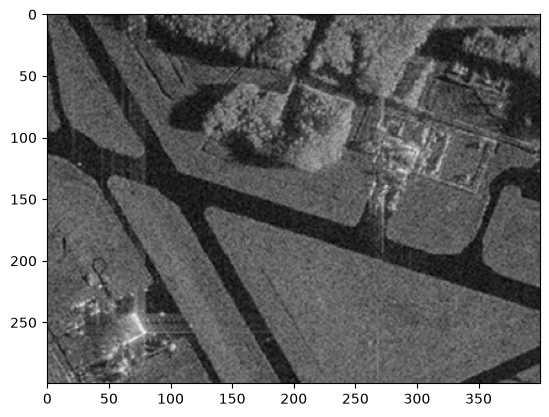

In [5]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import math

image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.imshow(image_gray, cmap="gray")
plt.show()

In [6]:
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0]) 
    if abs(av_val - img[point]) <= T:
        return True
    return False

In [7]:
def region_growing(image, seed_point, homo_fun, r, T):
    mask = np.zeros(image_gray.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    while count > 0:
        count = 0
        local_mask = np.zeros(image_gray.shape, np.uint8)
        for i in range(r, image.shape[0] - r):
            for j in range(r, image.shape[1] - r):
                if mask[i,j] == 0 and mask[i-r:i+r, j-r:j+r].sum() > 0:
                    if homo_fun(image, mask, (i,j), T):
                        local_mask[i,j] = 1
        count = np.count_nonzero(local_mask)
        print(count)
        mask += local_mask

    return mask * 255

In [17]:
seed_point = (125, 125)
mask = region_growing(image_gray, seed_point, homo_average, 4, 20)

59
150
189
216
255
263
251
261
269
256
209
214
238
253
309
305
395
428
413
524
463
485
514
602
674
791
806
756
756
889
843
855
896
890
932
967
1087
1325
1365
1419
1292
1194
1208
1189
1611
1384
1558
1587
1619
1655
1723
2093
1446
1425
1402
1469
1490
1431
1506
1493
1466
2179
1583
1651
1852
1918
1880
1637
1022
561
515
561
1246
378
311
211
194
180
172
166
152
140
119
107
98
91
79
63
44
25
0


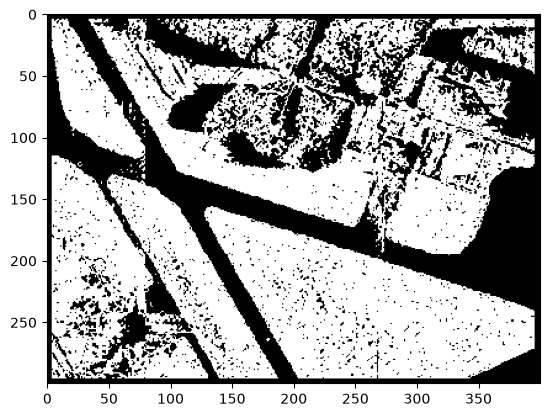

In [18]:
plt.imshow(mask, cmap="gray")
plt.show()

In [19]:
def homo_median(img, mask, point, T):
    med_val = np.median(img[mask > 0])

    if abs(med_val - img[point]) <= T:
        return True

    return False

In [20]:
seed_point = (125, 125)
mask2 = region_growing(image_gray, seed_point, homo_median, 4, 20)

59
150
190
217
255
268
258
261
269
256
210
219
245
256
312
312
403
437
422
519
469
490
519
606
679
798
812
764
762
908
853
863
903
899
932
1091
1070
1178
1354
1474
1369
1247
1543
1235
1284
1405
1578
1605
1994
1654
1758
1623
1469
1452
1404
1476
1516
1464
2051
1520
1496
1615
1600
1717
1911
1911
2516
1644
1029
559
548
567
447
380
313
212
196
183
173
166
152
140
121
108
98
91
79
63
44
25
0


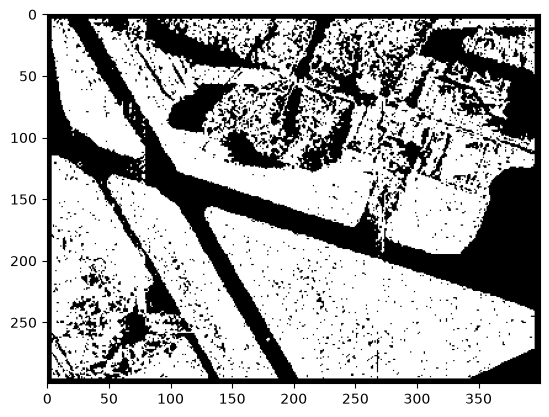

In [21]:
plt.imshow(mask2, cmap="gray")
plt.show()

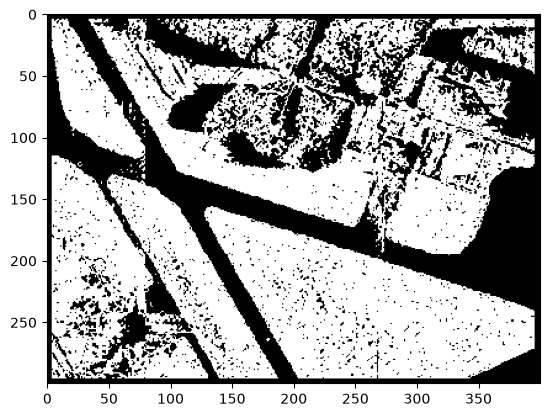

In [22]:
plt.imshow(mask, cmap="gray")
plt.show()

In [1]:
print("homo_average - чувствителен к шуму, homo_median - более устойчив к выбросам")
print("Медиана дала лучше результат, так как меньше точек шума, но разница не очень велика")


homo_average - чувствителен к шуму, homo_median - более устойчив к выбросам
Медиана дала лучше результат, так как меньше точек шума, но разница не очень велика


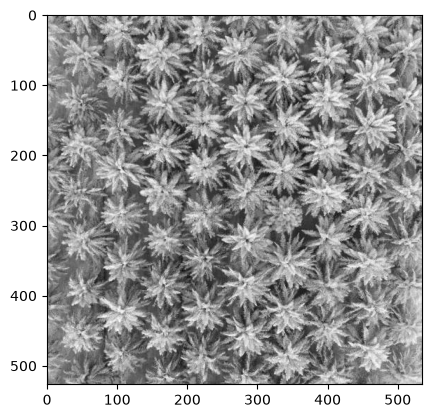

In [60]:
palm = cv2.imread('palm_1.jpg')
palm_gray = cv2.cvtColor(palm, cv2.COLOR_BGR2GRAY)

plt.imshow(palm_gray, cmap="gray")
plt.show()

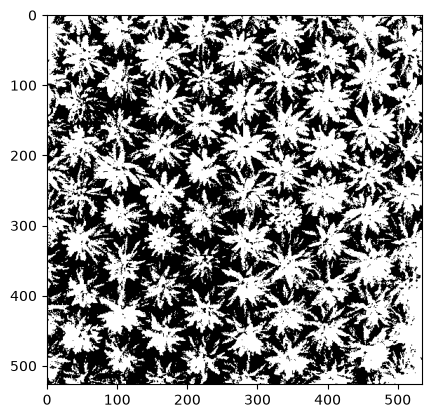

In [62]:
ret, thresh = cv2.threshold(palm_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

plt.imshow(thresh, cmap="gray")
plt.show()


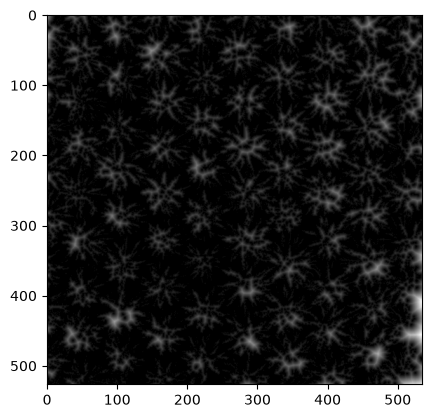

In [156]:
dist = cv2.distanceTransform(thresh, cv2.DIST_L2, 5)

plt.imshow(dist, cmap="gray")
plt.show()

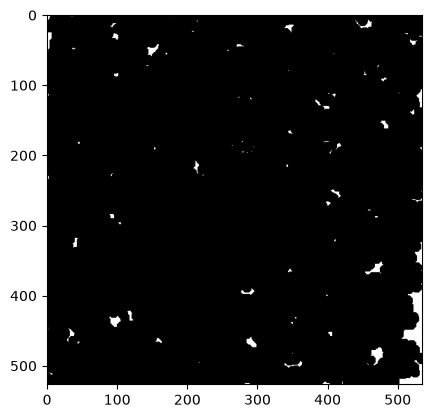

In [166]:
ret, sure_fg = cv2.threshold(dist, 0.35 * dist.max(), 255, cv2.THRESH_BINARY)
sure_fg = sure_fg.astype(np.uint8)

plt.imshow(sure_fg, cmap="gray")
plt.show()

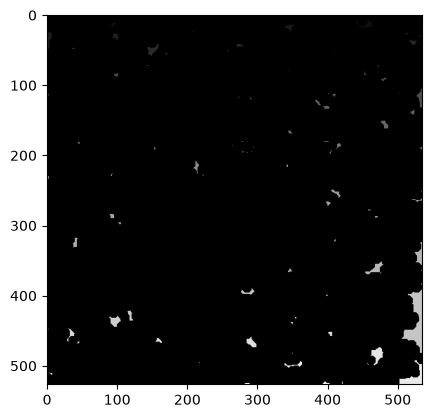

In [167]:
ret, markers = cv2.connectedComponents(sure_fg)

plt.imshow(markers, cmap="gray")
plt.show()

In [168]:
print("Деревьев:", ret - 1)   

Деревьев: 96


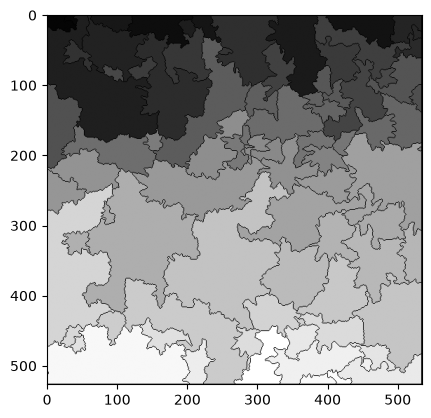

In [169]:
markers = cv2.watershed(palm, markers)

plt.imshow(markers, cmap="gray")
plt.show()

In [170]:
print("Пальмы - неровные объекты и разбиваются на лучи, поэтому поставить одну точку на каждую трудно")
print("порог 0,35 оказался самым удачным, так как при попроге меньше было очень много точек, а при пороге больше - слишком мало")

Пальмы - неровные объекты и разбиваются на лучи, поэтому поставить одну точку на каждую трудно
порог 0,35 оказался самым удачным, так как при попроге меньше было очень много точек, а при пороге больше - слишком мало
